# DeepVelo Tool Testing

### By: Josh Navarro

Following the tutorial of BOWANG-LAB / DeepVelo, LINK TO GITHUB: https://github.com/bowang-lab/DeepVelo
LINK TO ARTICLE: https://link.springer.com/article/10.1186/s13059-023-03148-9

In [ ]:
# Download the needed pacakges(RUN ONCE)
'''
import sys
!{sys.executable} -m pip install deepvelo
!{sys.executable} -m pip uninstall dgl
!{sys.executable} -m pip install "dgl-cu101>=0.4.3,<0.7"
'''

^C


##### Creating the environment

1 Install the miniconda

2 Open the anaconda terminal

3 Create the python 3.9 environment
conda create -n deepvelo_env python=3.9 -y

Activate it:
conda activate deepvelo_env

4 Upgrade the pip
python -m pip install --upgrade pip

5 Install the hnswlib using the Conda

conda install -c conda-forge hnswlib=0.7.0 -y

Verify:
python -c "import hnswlib; print('hnswlib works')"

6 Install the DeepVelo
python -m pip install deepvelo --no-deps

Install the packages seperately
python -m pip install "numpy<2" "torch<1.13" "scvelo==0.2.5" "scanpy<1.10" "umap-learn<=0.5.4" "matplotlib<3.6" "seaborn<0.12" "adjustText==0.7.3" tqdm

Install DGL
python -m pip install "dgl<0.9"

7 Install Jupyter Support

python -m pip install jupyter ipykernel

Register the environment
python -m ipykernel install --user --name deepvelo_env --display-name "Python 3.9 - DeepVelo"


Had to force reinstall 
python -m pip install --force-reinstall "numpy==1.21.6"
python -m pip install --force-reinstall "pandas==1.4.4"

Then did this
python -m pip uninstall numpy pandas -y
conda install -c conda-forge numpy=1.21.6 pandas=1.4.4 scipy=1.7.3 -y

In [1]:
# Import that we will be using
import anndata as ann
import deepvelo as dv
import scvelo as scv
import numpy as np
import scanpy as sc
import sys

Using backend: pytorch


In [2]:
import matplotlib
import IPython
import ipykernel
import matplotlib_inline

print("Matplotlib:", matplotlib.__version__)
print("IPython:", IPython.__version__)
print("ipykernel:", ipykernel.__version__)
print("matplotlib-inline:", matplotlib_inline.__version__)

Matplotlib: 3.5.3
IPython: 8.18.1
ipykernel: 6.31.0
matplotlib-inline: 0.1.6


In [3]:
# Check the versions 
print("Python:", sys.version)
print("NumPy:", np.__version__)
print("AnnData:", ann.__version__)
print("scVelo:", scv.__version__)

Python: 3.9.25 (main, Nov  3 2025, 22:44:01) [MSC v.1929 64 bit (AMD64)]
NumPy: 1.23.5
AnnData: 0.10.9
scVelo: 0.2.5


### Minimal Example

In [5]:
# Read the data
adata = ann.read_h5ad(r"C:\Users\joshu\Desktop\RNA_Velocity_R\veloVI-20260709T175737Z-2-001\janssens_2025_CellRanger_Velocyto_counts_eLNP.h5ad")

In [16]:
# Preprocess the data
scv.pp.filter_and_normalize(
    adata, 
    min_shared_counts = 20, 
    n_top_genes = 2000 # Filters for the top 2000 genes
)
scv.pp.moments(
    adata, 
    n_neighbors = 30, # Looks at the 30 nearest neighbors
    n_pcs = 30 # Looks at the 30 principle components
)

Filtered out 24049 genes that are detected 20 counts (shared).
Extracted 2000 highly variable genes.
Logarithmized X.
computing moments based on connectivities
    finished (0:00:05) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


In [6]:
# Check the data
adata.obs.head()

,orig.ident,nCount_RNA,nFeature_RNA,sum,detected,subsets_Mito_sum,subsets_Mito_detected,subsets_Mito_percent,subsets_RBC_sum,subsets_RBC_detected,...,newClustersTmp,newClusters,annotated_clusters_paper_2024,annotated_clusters_Muscat_paper_2024,annotated_clusters_Muscat_v2_paper_2024,newClusters_paper_2024,Cell_ID,_scvi_batch,_scvi_labels,Experimental_condition
CellID,,,,,,,,,,,,,,,,,,,,,
AAAGGGCTCTGAGCAT-6,VBO009,7549,2074,7549,2074,143,9,1.894291,0,0,...,Immature cDC1s,Immature cDC1s_eLNPs_2h,Immature cDC1s,Immature cDC1s,eLNPs_2h_Immature cDC1s,Immature cDC1s_eLNPs_2h,AAAGGGCTCTGAGCAT-6,0,0,eLNP
AAACCCAAGGGAGTTC-6,VBO009,7461,1732,7461,1732,122,10,1.635170,0,0,...,Late mature cDC1s,Late mature cDC1s_eLNPs_2h,Tmem176+ late mature cDC1s,Late mature cDC1s,eLNPs_2h_Late mature cDC1s,Late mature cDC1s_eLNPs_2h,AAACCCAAGGGAGTTC-6,0,0,eLNP
AAAGGATTCACCCTCA-6,VBO009,6795,1923,6795,1923,86,8,1.265636,0,0,...,Immature cDC1s,Immature cDC1s_eLNPs_2h,Immature cDC1s,Immature cDC1s,eLNPs_2h_Immature cDC1s,Immature cDC1s_eLNPs_2h,AAAGGATTCACCCTCA-6,0,0,eLNP
AAAGGTATCTCTCGAC-6,VBO009,4724,1717,4724,1717,91,11,1.926334,0,0,...,Immature cDC1s,Immature cDC1s_eLNPs_2h,Immature cDC1s,Immature cDC1s,eLNPs_2h_Immature cDC1s,Immature cDC1s_eLNPs_2h,AAAGGTATCTCTCGAC-6,0,0,eLNP
AAACGAACAACAAAGT-6,VBO009,7076,1919,7076,1919,151,10,2.133974,0,0,...,Early mature cDC1s,Early mature cDC1s_eLNPs_2h,Il12b+ cDC1s,Early mature cDC1s,eLNPs_2h_Early mature cDC1s,Early mature cDC1s_eLNPs_2h,AAACGAACAACAAAGT-6,0,0,eLNP


In [7]:
# Check the columns
print(adata.obs.columns.tolist())

['orig.ident', 'nCount_RNA', 'nFeature_RNA', 'sum', 'detected', 'subsets_Mito_sum', 'subsets_Mito_detected', 'subsets_Mito_percent', 'subsets_RBC_sum', 'subsets_RBC_detected', 'subsets_RBC_percent', 'subsets_COVID_sum', 'subsets_COVID_detected', 'subsets_COVID_percent', 'total', 'sizeFactor', 'nCount_RNA.y', 'nFeature_RNA.y', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'SCT_snn_res.0', 'SCT_snn_res.0.1', 'SCT_snn_res.0.2', 'SCT_snn_res.0.3', 'SCT_snn_res.0.4', 'SCT_snn_res.0.5', 'SCT_snn_res.0.6', 'SCT_snn_res.0.7', 'SCT_snn_res.0.9', 'SCT_snn_res.1', 'SCT_clusters', 'fzero', 'pca.drop', 'pANN_0.25_0.13_181', 'DFPrediction', 'nCount_ADT', 'nFeature_ADT', 'ADT_snn_res.0.8', 'ADT_snn_res.0', 'ADT_snn_res.0.1', 'ADT_snn_res.0.2', 'ADT_snn_res.0.3', 'ADT_snn_res.0.4', 'ADT_snn_res.0.5', 'ADT_snn_res.0.6', 'ADT_snn_res.0.7', 'ADT_snn_res.0.9', 'ADT_snn_res.1', 'ADT_clusters', 'nCount_HTO', 'nFeature_HTO', 'HTO_maxID', 'HTO_secondID', 'HTO_margin', 'HTO_classification

In [17]:
# Run the DeepVelo using the default configs
'''
trainer = dv.train(
    adata, 
    dv.Constants.default_configs
)
'''
# THis will train the model and predict the velocity vector

'\ntrainer = dv.train(\n    adata, \n    dv.Constants.default_configs\n)\n'

In [18]:
# Create a umap
sc.pp.neighbors(
    adata,
    n_neighbors=30,
    n_pcs=30
)

sc.tl.umap(adata)

In [19]:
# Confirm the umap was created
print("X_umap" in adata.obsm)
print(adata.obsm["X_umap"].shape)

True
(21327, 2)


In [20]:
scv.tl.velocity_graph(
    adata,
    n_jobs=4
)

computing velocity graph (using 4/8 cores)


  0%|          | 0/21327 [00:00<?, ?cells/s]

    finished (0:00:32) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


computing velocity embedding
    finished (0:00:02) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


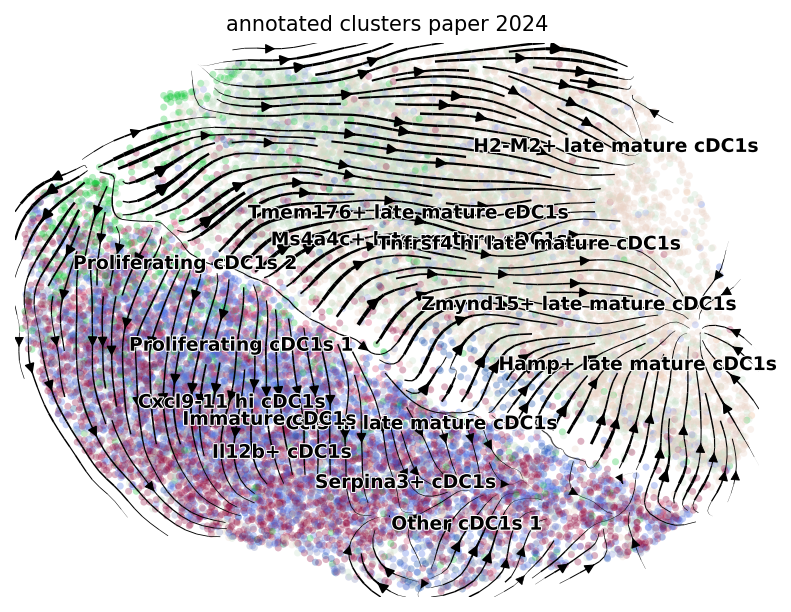

In [21]:
# Plot the velocity results
scv.pl.velocity_embedding_stream(
    adata,
    basis = "umap",
    color = "annotated_clusters_paper_2024",
    legend_fontsize = 9,
    dpi = 150
)

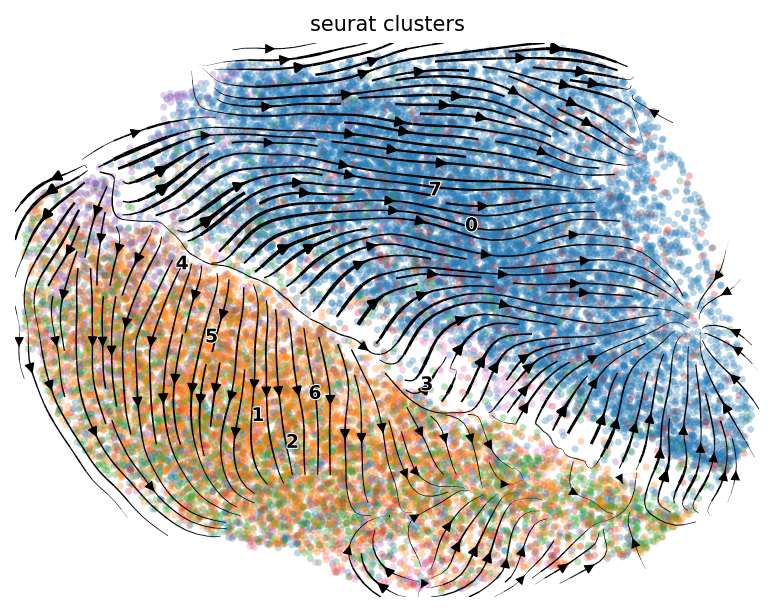

In [22]:
scv.pl.velocity_embedding_stream(
    adata,
    basis = "umap",
    color = "seurat_clusters",
    legend_fontsize = 9,
    dpi = 150
)

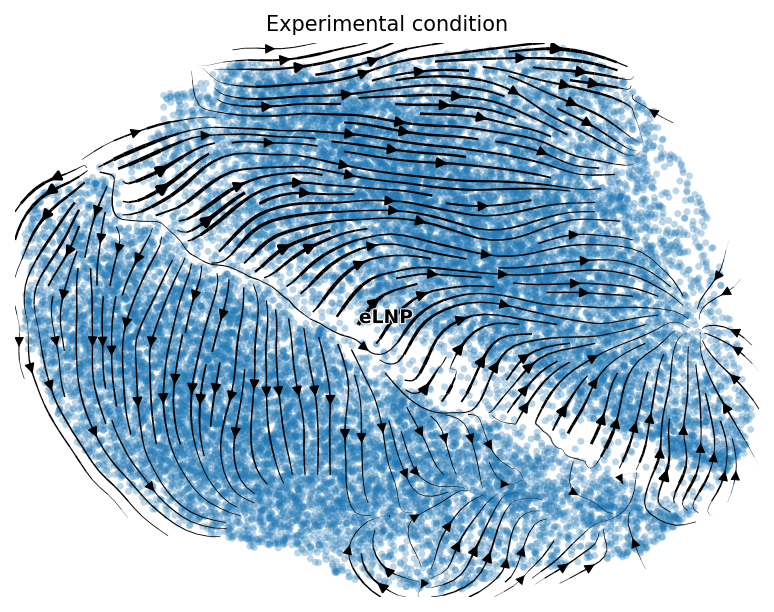

In [23]:
scv.pl.velocity_embedding_stream(
    adata,
    basis = "umap",
    color = "Experimental_condition",
    legend_fontsize = 9,
    dpi = 150
)

In [16]:
# Save the results into another file
adata.write_h5ad(
    r"C:\Users\joshu\Desktop\RNA_Velocity_R\deepvelo_results.h5ad"
)

Check the previous result

In [24]:
adata = ann.read_h5ad(r"C:\Users\joshu\Desktop\RNA_Velocity_R\DeepVelo\Short_DeepVelo\deepvelo_results.h5ad")

In [25]:
scv.tl.velocity_graph(
    adata,
    n_jobs=4
)

computing velocity graph (using 4/8 cores)


  0%|          | 0/21327 [00:00<?, ?cells/s]

    finished (0:00:51) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


computing velocity embedding
    finished (0:00:02) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


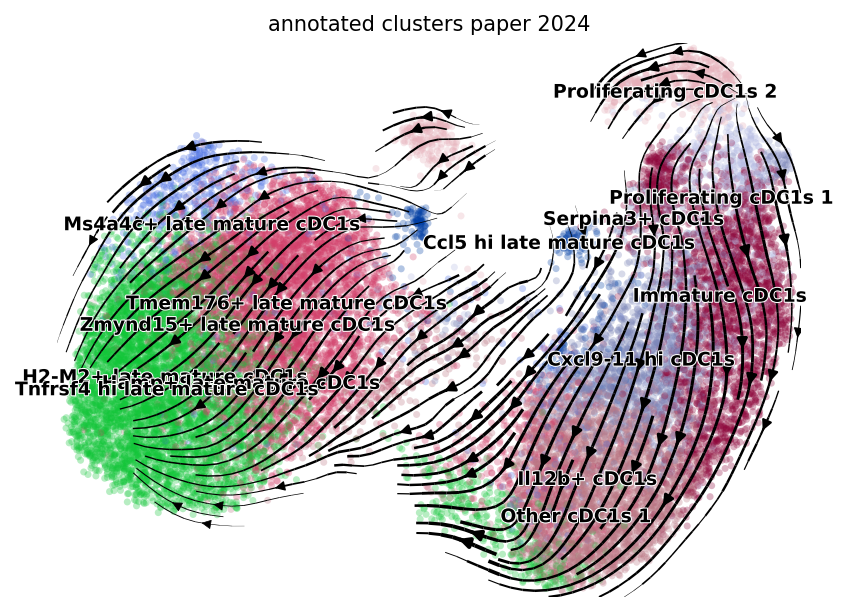

In [26]:
# Plot the velocity results
scv.pl.velocity_embedding_stream(
    adata,
    basis = "umap",
    color = "annotated_clusters_paper_2024",
    legend_fontsize = 9,
    dpi = 150
)